# Práctica 3 — Redes convolucionales (CNN) para clasificar MNIST

## Objetivos

Se sustituye el perceptrón multicapa de las prácticas 1 y 2 por **redes convolucionales** y se clasifica de nuevo el conjunto MNIST en sus **diez dígitos**. Se proponen diez arquitecturas que combinan las capas vistas en clase:

- **convolución** (`Conv2D`) con distintos tamaños de filtro, *stride* y *padding*;
- **agrupamiento** (`MaxPooling2D`, `AveragePooling2D` y `GlobalAveragePooling2D`);
- **funciones de activación** (`tanh`, `ReLU`);
- **normalización por lotes** (`BatchNormalization`);
- **Dropout** con tasas menores en la parte convolucional que en la densa.

Como referencia se incluye la red densa de la práctica 1 y una versión de **LeNet-5**. Las comparaciones están diseñadas por pares, de modo que cada par difiere en un único elemento. Para cada red se registran exactitud y errores en entrenamiento y validación, matriz de confusión, número de parámetros y tiempo de entrenamiento.

Igual que en la práctica 2, la mejor configuración se elige **exclusivamente con validación**; el test se reserva para estimar el rendimiento final. El mejor modelo se guarda en disco.

In [1]:
import gc
import os
import time
from pathlib import Path

BASE_DIR = Path.cwd()
if BASE_DIR.name != 'Practica-3' and (BASE_DIR / 'Practica-3').is_dir():
    BASE_DIR = BASE_DIR / 'Practica-3'
os.environ['KERAS_HOME'] = str(BASE_DIR / '.keras')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers

SEED = 42
BATCH_SIZE = 128
MAX_EPOCHS = 15
PATIENCE = 3
CLASSES = np.arange(10)

tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
plt.style.use('seaborn-v0_8-whitegrid')
np.set_printoptions(linewidth=140)
print('TensorFlow:', tf.__version__)
print('Dispositivos:', tf.config.list_physical_devices())

TensorFlow: 2.20.0
Dispositivos: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


## 1. Datos, separación y preprocesamiento

Se utilizan las mismas 60 000 imágenes de entrenamiento y 10 000 de test de MNIST que en las prácticas anteriores. Del entrenamiento original se apartan **600 imágenes de cada dígito** (6 000 en total) como validación estratificada con semilla fija; las 54 000 restantes ajustan los pesos. No existe solapamiento entre entrenamiento, validación y test.

Los píxeles se escalan a $[0,1]$ como antes. La diferencia con el MLP es la forma de la entrada: una capa `Conv2D` espera tensores `(alto, ancho, canales)`, por lo que cada imagen pasa de `(28, 28)` a `(28, 28, 1)` (un único canal de gris). Así la red conserva la **estructura espacial** de la imagen en lugar de aplanarla desde el principio.

Entrenamiento forma=(54000, 28, 28, 1) rango=[0.0, 1.0] por clase=[5323 6142 5358 5531 5242 4821 5318 5665 5251 5349]
Validación    forma=(6000, 28, 28, 1) rango=[0.0, 1.0] por clase=[600 600 600 600 600 600 600 600 600 600]
Test          forma=(10000, 28, 28, 1) rango=[0.0, 1.0] por clase=[ 980 1135 1032 1010  982  892  958 1028  974 1009]


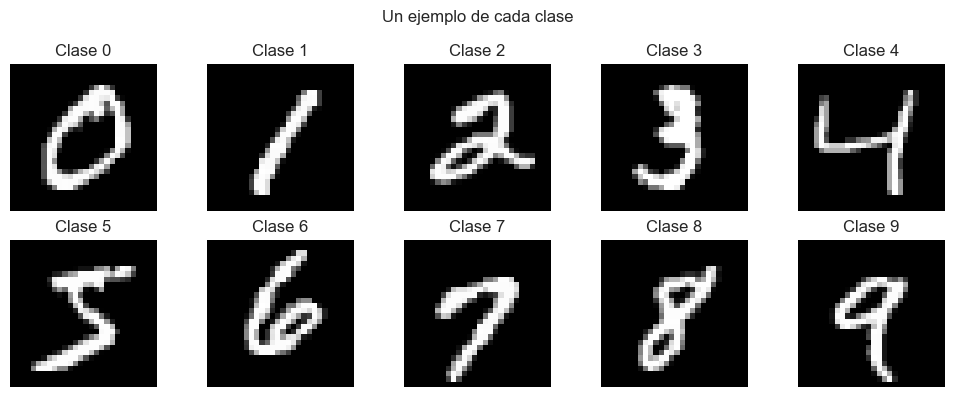

In [2]:
(images_train, digits_train), (images_test, digits_test) = tf.keras.datasets.mnist.load_data()
if images_train.shape != (60_000, 28, 28) or images_test.shape != (10_000, 28, 28):
    raise ValueError('Dimensiones inesperadas en MNIST')
if not (np.isin(digits_train, CLASSES).all() and np.isin(digits_test, CLASSES).all()):
    raise ValueError('Las etiquetas deben representar dígitos entre 0 y 9')

rng = np.random.default_rng(SEED)
validation_indices = rng.permutation(np.concatenate([
    rng.permutation(np.flatnonzero(digits_train == digit))[:600] for digit in CLASSES
]))
fit_mask = np.ones(len(digits_train), dtype=bool)
fit_mask[validation_indices] = False

def preprocess(images):
    return (images.astype('float32') / 255.0)[..., np.newaxis]

x_fit, y_fit = preprocess(images_train[fit_mask]), digits_train[fit_mask].astype('int32')
x_val, y_val = preprocess(images_train[validation_indices]), digits_train[validation_indices].astype('int32')
x_test, y_test = preprocess(images_test), digits_test.astype('int32')

for name, x, y in (('Entrenamiento', x_fit, y_fit), ('Validación', x_val, y_val), ('Test', x_test, y_test)):
    print(f'{name:<13} forma={x.shape} rango=[{x.min():.1f}, {x.max():.1f}] por clase={np.bincount(y, minlength=10)}')
assert len(x_fit) + len(x_val) == 60_000 and len(x_test) == 10_000
assert len(np.intersect1d(np.flatnonzero(fit_mask), validation_indices)) == 0

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for digit, ax in zip(CLASSES, axes.flat):
    ax.imshow(x_fit[np.flatnonzero(y_fit == digit)[0], ..., 0], cmap='gray')
    ax.set_title(f'Clase {digit}')
    ax.axis('off')
plt.suptitle('Un ejemplo de cada clase')
plt.tight_layout()
plt.show()

## 2. Arquitecturas propuestas

Una capa densa conecta cada píxel con cada neurona y no es invariante a traslaciones. Una convolución aplica el **mismo filtro pequeño** en todas las posiciones (localidad y pesos compartidos): detecta un trazo con independencia de dónde aparezca y con muchos menos parámetros. El agrupamiento reduce la resolución y aporta robustez frente a pequeños desplazamientos.

El tamaño espacial de salida de una convolución o agrupamiento es

$$\text{salida} = \left\lfloor \frac{\text{entrada} - \text{kernel} + 2\,\text{padding}}{\text{stride}} \right\rfloor + 1 .$$

Por ejemplo, en `cnn-2conv-maxpool`: $28 \xrightarrow{\text{conv }3\times3} 26 \xrightarrow{\text{pool }2\times2} 13 \xrightarrow{\text{conv }3\times3} 11 \xrightarrow{\text{pool }2\times2} 5$, de modo que `Flatten` produce $5\cdot5\cdot64 = 1600$ valores. Con *padding* `same` y *stride* 1 el tamaño se conserva.

| # | Nombre | Arquitectura (antes de la salida `Dense(10, softmax)`) | Qué se estudia |
|:-:|:--|:--|:--|
| 1 | `mlp-referencia` | Flatten → Dense 128 | Red densa de la práctica 1 (sin convolución) |
| 2 | `lenet5` | Conv 6@5×5 tanh (`same`) → AvgPool → Conv 16@5×5 tanh → AvgPool → Dense 120 → Dense 84 (tanh) | CNN clásica de LeCun (1998) |
| 3 | `cnn-1conv` | Conv 32@3×3 → MaxPool → Dense 128 | Efecto de introducir **una** convolución (frente a 1) |
| 4 | `cnn-2conv-maxpool` | Conv 32 → MaxPool → Conv 64 → MaxPool → Dense 128 | Efecto de la **profundidad** (frente a 3) |
| 5 | `cnn-2conv-avgpool` | Igual que 4 con AvgPool | **Max** frente a **average** pooling |
| 6 | `cnn-2conv-stride2` | Conv 32 (*stride* 2) → Conv 64 (*stride* 2) → Dense 128 | Reducir con ***stride*** en vez de pooling |
| 7 | `cnn-2conv-dropout` | 4 + Dropout 0,25 tras cada pooling y 0,5 tras la densa | Regularización con **Dropout** |
| 8 | `cnn-2conv-bn-dropout` | 7 + Conv sin sesgo → BatchNorm → ReLU | Efecto de **BatchNormalization** |
| 9 | `cnn-bn-gap` | 3 bloques Conv-BN-ReLU `same` (32, 64, 128) con 2 MaxPool → GlobalAvgPool | Sustituir Flatten + densa por **Global Average Pooling** |
| 10 | `vgg-bn-dropout` | 2 bloques tipo VGG: [Conv-BN-ReLU ×2 → MaxPool → Dropout 0,25] (32 y 64 filtros) → Dense 128 → Dropout 0,5 | **Bloques más profundos** de filtros 3×3 |

Siguiendo las diapositivas, BatchNormalization se coloca **después de la convolución y antes de la activación**, y esa convolución no usa sesgo (BN ya incluye un desplazamiento aprendible). Dropout se sitúa tras las capas de pooling y con tasa menor en la parte convolucional que en la densa. Salvo en LeNet-5, que conserva `tanh`, todas las capas ocultas usan ReLU.

In [3]:
def conv(filters, kernel_size=3, *, batch_norm=False, **kwargs):
    if batch_norm:
        return [layers.Conv2D(filters, kernel_size, use_bias=False, **kwargs),
                layers.BatchNormalization(), layers.Activation('relu')]
    return [layers.Conv2D(filters, kernel_size, activation='relu', **kwargs)]


def dense(units, dropout=0.0):
    return [layers.Dense(units, activation='relu')] + ([layers.Dropout(dropout)] if dropout else [])


ARCHITECTURES = {
    'mlp-referencia': lambda: [layers.Flatten(), *dense(128)],
    'lenet5': lambda: [
        layers.Conv2D(6, 5, padding='same', activation='tanh'), layers.AveragePooling2D(2),
        layers.Conv2D(16, 5, activation='tanh'), layers.AveragePooling2D(2),
        layers.Flatten(), layers.Dense(120, activation='tanh'), layers.Dense(84, activation='tanh'),
    ],
    'cnn-1conv': lambda: [*conv(32), layers.MaxPooling2D(2), layers.Flatten(), *dense(128)],
    'cnn-2conv-maxpool': lambda: [
        *conv(32), layers.MaxPooling2D(2), *conv(64), layers.MaxPooling2D(2), layers.Flatten(), *dense(128),
    ],
    'cnn-2conv-avgpool': lambda: [
        *conv(32), layers.AveragePooling2D(2), *conv(64), layers.AveragePooling2D(2), layers.Flatten(), *dense(128),
    ],
    'cnn-2conv-stride2': lambda: [*conv(32, strides=2), *conv(64, strides=2), layers.Flatten(), *dense(128)],
    'cnn-2conv-dropout': lambda: [
        *conv(32), layers.MaxPooling2D(2), layers.Dropout(0.25),
        *conv(64), layers.MaxPooling2D(2), layers.Dropout(0.25),
        layers.Flatten(), *dense(128, dropout=0.5),
    ],
    'cnn-2conv-bn-dropout': lambda: [
        *conv(32, batch_norm=True), layers.MaxPooling2D(2), layers.Dropout(0.25),
        *conv(64, batch_norm=True), layers.MaxPooling2D(2), layers.Dropout(0.25),
        layers.Flatten(), *dense(128, dropout=0.5),
    ],
    'cnn-bn-gap': lambda: [
        *conv(32, padding='same', batch_norm=True), layers.MaxPooling2D(2),
        *conv(64, padding='same', batch_norm=True), layers.MaxPooling2D(2),
        *conv(128, padding='same', batch_norm=True), layers.GlobalAveragePooling2D(),
    ],
    'vgg-bn-dropout': lambda: [
        *conv(32, padding='same', batch_norm=True), *conv(32, padding='same', batch_norm=True),
        layers.MaxPooling2D(2), layers.Dropout(0.25),
        *conv(64, padding='same', batch_norm=True), *conv(64, padding='same', batch_norm=True),
        layers.MaxPooling2D(2), layers.Dropout(0.25),
        layers.Flatten(), *dense(128, dropout=0.5),
    ],
}


def build_model(name):
    model = tf.keras.Sequential(
        [layers.Input(shape=(28, 28, 1)), *ARCHITECTURES[name](), layers.Dense(10, activation='softmax')],
        name=name.replace('-', '_'),
    )
    model.compile(optimizer=tf.keras.optimizers.Adam(), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model


def evaluate_predictions(model, x, y):
    predictions = np.argmax(model.predict(x, batch_size=512, verbose=0), axis=1)
    matrix = np.zeros((10, 10), dtype=np.int64)
    np.add.at(matrix, (y, predictions), 1)
    errors = int(np.count_nonzero(predictions != y))
    accuracy = float(np.mean(predictions == y))
    if matrix.sum() != len(y) or errors != len(y) - np.trace(matrix):
        raise RuntimeError('Las métricas y la matriz de confusión no concuerdan')
    return accuracy, errors, matrix, predictions


summary = []
for name in ARCHITECTURES:
    model = build_model(name)
    summary.append({
        'configuration': name,
        'capas': len(model.layers),
        'conv2d': sum(isinstance(layer, layers.Conv2D) for layer in model.layers),
        'parametros': model.count_params(),
        'forma_antes_densa': str(next(
            (layer.output.shape[1:] for layer in reversed(model.layers)
             if isinstance(layer, (layers.Flatten, layers.GlobalAveragePooling2D))), None)),
    })
tf.keras.backend.clear_session()
pd.DataFrame(summary)

,configuration,capas,conv2d,parametros,forma_antes_densa
0,mlp-referencia,3,0,101770,"(784,)"
1,lenet5,8,2,61706,"(400,)"
2,cnn-1conv,5,1,693962,"(5408,)"
3,cnn-2conv-maxpool,7,2,225034,"(1600,)"
4,cnn-2conv-avgpool,7,2,225034,"(1600,)"
5,cnn-2conv-stride2,5,2,315146,"(2304,)"
6,cnn-2conv-dropout,10,2,225034,"(1600,)"
7,cnn-2conv-bn-dropout,14,2,225322,"(1600,)"
8,cnn-bn-gap,13,3,94634,"(128,)"
9,vgg-bn-dropout,20,4,468394,"(3136,)"


In [4]:
build_model('cnn-2conv-maxpool').summary()

Model: "cnn_2conv_maxpool"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

## 3. Entrenamiento y selección por validación

Todas las redes comparten exactamente las mismas condiciones, de modo que las diferencias se deben a la arquitectura:

- mismos datos y preprocesamiento; optimizador **Adam** (tasa por defecto) y lote **128**, la mejor combinación de la práctica 1;
- misma semilla antes de construir cada modelo y ejecución determinista de TensorFlow;
- hasta **15 épocas** con **parada temprana** si la pérdida de validación no mejora en 3 épocas, restaurando los mejores pesos (las redes más regularizadas pueden necesitar más épocas y las demás no se sobreentrenan);
- el tiempo mide únicamente `fit` (en CPU; es orientativo y depende del equipo).

Las métricas de entrenamiento se recalculan tras `fit` con `predict`, es decir, **sin Dropout y con las estadísticas finales de BatchNorm**, para que sean comparables entre redes. El criterio de selección es la exactitud de validación; en caso de empate, menor pérdida de validación y después menor tiempo. El mejor modelo se escribe en disco en cuanto mejora ese criterio.

Las predicciones de test se calculan en el mismo bucle para no tener que reentrenar, pero **se guardan aparte y no intervienen en la selección**; solo se muestran en la sección 5, una vez elegido el ganador.

In [5]:
results = []
test_results = {}
histories = {}
confusion_matrices = {}
model_path = BASE_DIR / 'mejor_modelo_cnn_mnist.keras'
best_score = (-np.inf, -np.inf, -np.inf)
best_name = None

for run, name in enumerate(ARCHITECTURES, start=1):
    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(SEED)
    model = build_model(name)
    early_stopping = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True)
    start = time.perf_counter()
    history = model.fit(
        x_fit, y_fit, validation_data=(x_val, y_val), epochs=MAX_EPOCHS, batch_size=BATCH_SIZE,
        callbacks=[early_stopping], shuffle=True, verbose=0,
    )
    elapsed = time.perf_counter() - start

    train_accuracy, train_errors, train_matrix, _ = evaluate_predictions(model, x_fit, y_fit)
    val_accuracy, val_errors, val_matrix, _ = evaluate_predictions(model, x_val, y_val)
    val_loss = float(model.evaluate(x_val, y_val, batch_size=512, verbose=0)[0])
    epochs_run = len(history.history['loss'])
    results.append({
        'configuration': name,
        'parameters': model.count_params(),
        'epochs_run': epochs_run,
        'restored_epoch': int(np.argmin(history.history['val_loss']) + 1),
        'train_accuracy': train_accuracy, 'train_errors': train_errors,
        'val_accuracy': val_accuracy, 'val_errors': val_errors, 'val_loss': val_loss,
        'train_seconds': elapsed, 'seconds_per_epoch': elapsed / epochs_run,
        'accuracy_gap': train_accuracy - val_accuracy,
    })
    histories[name] = history.history
    confusion_matrices[f'{name}_train'] = train_matrix
    confusion_matrices[f'{name}_val'] = val_matrix
    test_results[name] = evaluate_predictions(model, x_test, y_test)

    score = (val_accuracy, -val_loss, -elapsed)
    if score > best_score:
        model.save(model_path)
        best_score, best_name = score, name
    print(
        f'[{run:02d}/{len(ARCHITECTURES)}] {name:<21} train={train_accuracy:.4%} ({train_errors:>4} err) '
        f'val={val_accuracy:.4%} ({val_errors:>3} err) épocas={epochs_run:>2} tiempo={elapsed:6.1f}s'
    )
    del model

results_df = pd.DataFrame(results).sort_values(
    ['val_accuracy', 'val_loss', 'train_seconds'], ascending=[False, True, True]
).reset_index(drop=True)
assert best_name == results_df.iloc[0]['configuration']
print('\nSeleccionado por validación:', best_name)

[01/10] mlp-referencia        train=99.5741% ( 230 err) val=97.6833% (139 err) épocas=15 tiempo=   4.8s


[02/10] lenet5                train=99.3759% ( 337 err) val=97.9167% (125 err) épocas=10 tiempo=  25.5s


[03/10] cnn-1conv             train=99.3537% ( 349 err) val=98.2333% (106 err) épocas= 8 tiempo=  20.1s


[04/10] cnn-2conv-maxpool     train=99.5167% ( 261 err) val=98.8000% ( 72 err) épocas= 9 tiempo=  42.2s


[05/10] cnn-2conv-avgpool     train=99.3093% ( 373 err) val=98.6167% ( 83 err) épocas= 9 tiempo=  40.1s


[06/10] cnn-2conv-stride2     train=99.3185% ( 368 err) val=98.3500% ( 99 err) épocas= 7 tiempo=  12.7s


[07/10] cnn-2conv-dropout     train=99.6296% ( 200 err) val=98.8333% ( 70 err) épocas=14 tiempo=  71.9s


[08/10] cnn-2conv-bn-dropout  train=99.5907% ( 221 err) val=98.8667% ( 68 err) épocas=15 tiempo= 115.2s


[09/10] cnn-bn-gap            train=98.9704% ( 556 err) val=97.9333% (124 err) épocas=13 tiempo= 185.1s


[10/10] vgg-bn-dropout        train=99.3889% ( 330 err) val=98.9667% ( 62 err) épocas=10 tiempo= 363.2s

Seleccionado por validación: vgg-bn-dropout


## 4. Comparación numérica y gráfica

La tabla está ordenada de mejor a peor exactitud de validación. `accuracy_gap` = exactitud de entrenamiento − exactitud de validación: una brecha grande indica sobreajuste; exactitudes bajas en ambos conjuntos, subajuste.

,configuration,parameters,epochs_run,restored_epoch,train_accuracy,train_errors,val_accuracy,val_errors,val_loss,train_seconds,seconds_per_epoch,accuracy_gap
0,vgg-bn-dropout,"468,394",10,7,99.389%,330,98.967%,62,0.0381,363.2,36.32,0.422%
1,cnn-2conv-bn-dropout,"225,322",15,14,99.591%,221,98.867%,68,0.0419,115.2,7.68,0.724%
2,cnn-2conv-dropout,"225,034",14,11,99.630%,200,98.833%,70,0.0350,71.9,5.13,0.796%
3,cnn-2conv-maxpool,"225,034",9,6,99.517%,261,98.800%,72,0.0438,42.2,4.69,0.717%
4,cnn-2conv-avgpool,"225,034",9,6,99.309%,373,98.617%,83,0.0460,40.1,4.45,0.693%
5,cnn-2conv-stride2,"315,146",7,4,99.319%,368,98.350%,99,0.0560,12.7,1.81,0.969%
6,cnn-1conv,"693,962",8,5,99.354%,349,98.233%,106,0.0574,20.1,2.51,1.120%
7,cnn-bn-gap,"94,634",13,10,98.970%,556,97.933%,124,0.0689,185.1,14.24,1.037%
8,lenet5,"61,706",10,7,99.376%,337,97.917%,125,0.0583,25.5,2.55,1.459%
9,mlp-referencia,"101,770",15,13,99.574%,230,97.683%,139,0.0920,4.8,0.32,1.891%


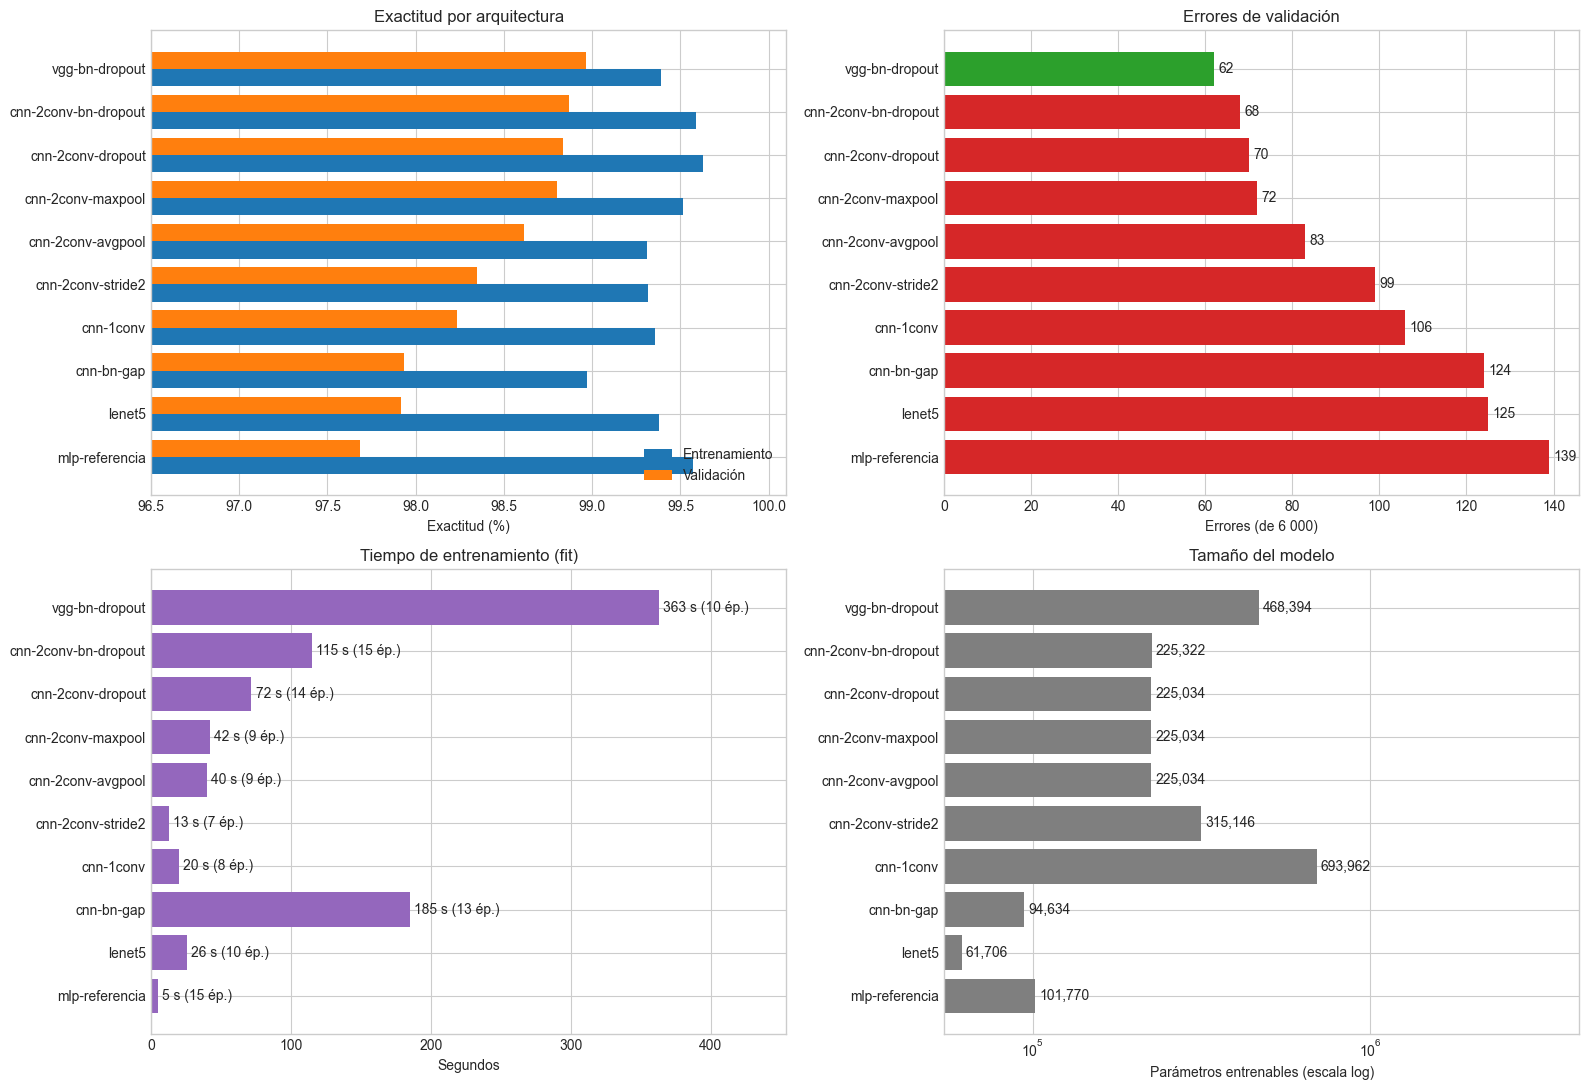

In [6]:
display(results_df.style.format({
    'parameters': '{:,}', 'train_accuracy': '{:.3%}', 'val_accuracy': '{:.3%}', 'val_loss': '{:.4f}',
    'train_seconds': '{:.1f}', 'seconds_per_epoch': '{:.2f}', 'accuracy_gap': '{:.3%}',
}).background_gradient(subset=['val_accuracy'], cmap='Greens'))

plot_df = results_df.sort_values('val_accuracy')
positions = np.arange(len(plot_df))
is_best = plot_df['configuration'].eq(best_name).to_numpy()
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
ax = axes[0, 0]
ax.barh(positions - 0.2, plot_df['train_accuracy'] * 100, height=0.4, label='Entrenamiento')
ax.barh(positions + 0.2, plot_df['val_accuracy'] * 100, height=0.4, label='Validación')
ax.set(yticks=positions, yticklabels=plot_df['configuration'], xlabel='Exactitud (%)',
       title='Exactitud por arquitectura',
       xlim=(np.floor(plot_df[['train_accuracy', 'val_accuracy']].min().min() * 100) - 0.5, 100.1))
ax.legend(loc='lower right')
ax = axes[0, 1]
bars = ax.barh(positions, plot_df['val_errors'], color=np.where(is_best, 'tab:green', 'tab:red'))
ax.bar_label(bars, padding=3)
ax.set(yticks=positions, yticklabels=plot_df['configuration'], xlabel='Errores (de 6 000)', title='Errores de validación')
ax = axes[1, 0]
bars = ax.barh(positions, plot_df['train_seconds'], color='tab:purple')
ax.bar_label(bars, labels=[f'{s:.0f} s ({e} ép.)' for s, e in zip(plot_df['train_seconds'], plot_df['epochs_run'])], padding=3)
ax.set(yticks=positions, yticklabels=plot_df['configuration'], xlabel='Segundos', title='Tiempo de entrenamiento (fit)')
ax.set_xlim(0, plot_df['train_seconds'].max() * 1.25)
ax = axes[1, 1]
bars = ax.barh(positions, plot_df['parameters'], color='tab:gray')
ax.bar_label(bars, labels=[f'{p:,}' for p in plot_df['parameters']], padding=3)
ax.set(yticks=positions, yticklabels=plot_df['configuration'], xlabel='Parámetros entrenables (escala log)',
       title='Tamaño del modelo', xscale='log')
ax.set_xlim(right=plot_df['parameters'].max() * 6)
plt.tight_layout()
plt.show()

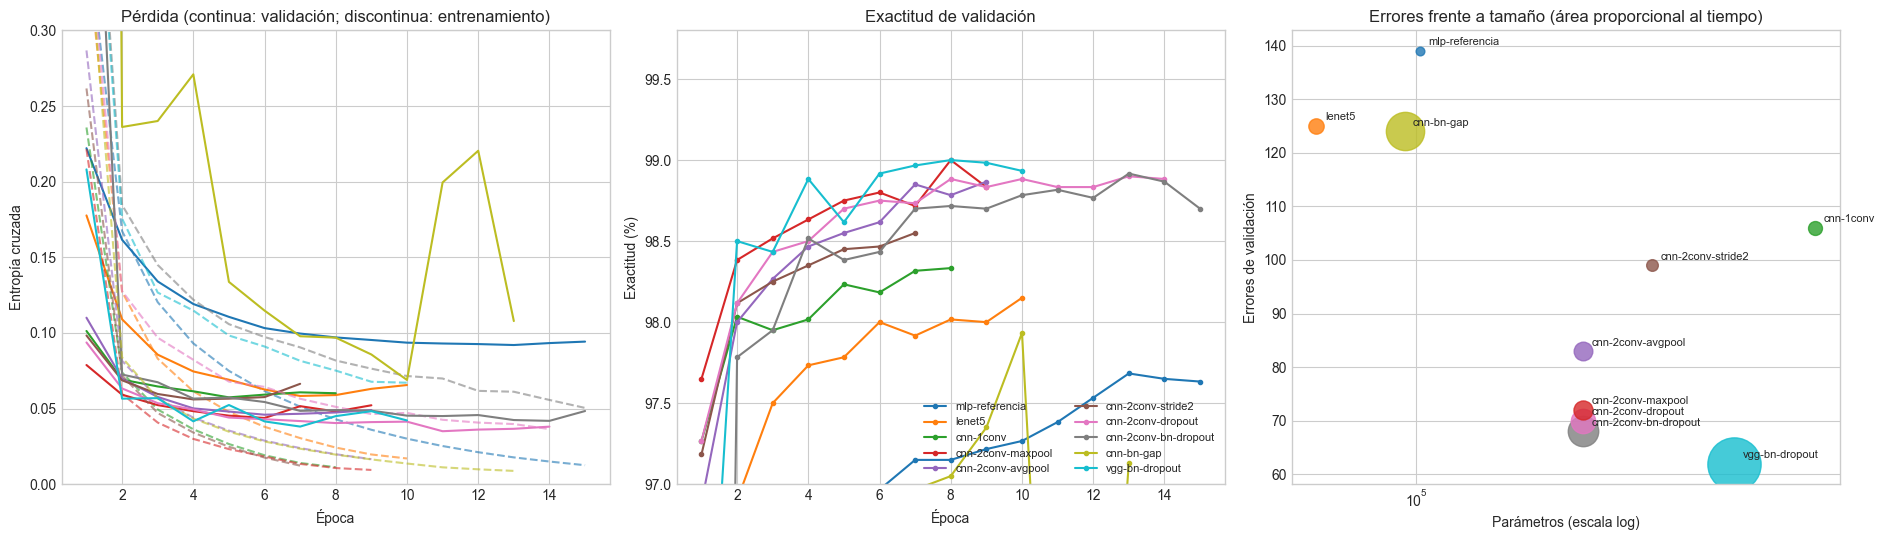

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
cmap = plt.get_cmap('tab10')
for i, (name, history) in enumerate(histories.items()):
    epochs = np.arange(1, len(history['loss']) + 1)
    axes[0].plot(epochs, history['loss'], color=cmap(i), linestyle='--', alpha=0.6)
    axes[0].plot(epochs, history['val_loss'], color=cmap(i), label=name)
    axes[1].plot(epochs, np.array(history['val_accuracy']) * 100, color=cmap(i), marker='.', label=name)
axes[0].set(xlabel='Época', ylabel='Entropía cruzada', title='Pérdida (continua: validación; discontinua: entrenamiento)', ylim=(0, 0.3))
axes[1].set(xlabel='Época', ylabel='Exactitud (%)', title='Exactitud de validación', ylim=(97, 99.8))
axes[1].legend(fontsize=8, ncol=2, loc='lower right')

ax = axes[2]
for i, row in results_df.iterrows():
    color = cmap(list(ARCHITECTURES).index(row['configuration']))
    ax.scatter(row['parameters'], row['val_errors'], s=row['train_seconds'] * 4 + 20, color=color, alpha=0.8)
    ax.annotate(row['configuration'], (row['parameters'], row['val_errors']), fontsize=8,
                xytext=(6, 4), textcoords='offset points')
ax.set(xscale='log', xlabel='Parámetros (escala log)', ylabel='Errores de validación',
       title='Errores frente a tamaño (área proporcional al tiempo)')
plt.tight_layout()
plt.show()

### Matrices de confusión

Convención: filas = clase real, columnas = predicción. Cada celda muestra el recuento absoluto; el color se normaliza por fila. Se muestran las matrices de validación de todas las redes y, después, las de entrenamiento y validación de cada una en el fichero `matrices_confusion.npz`.

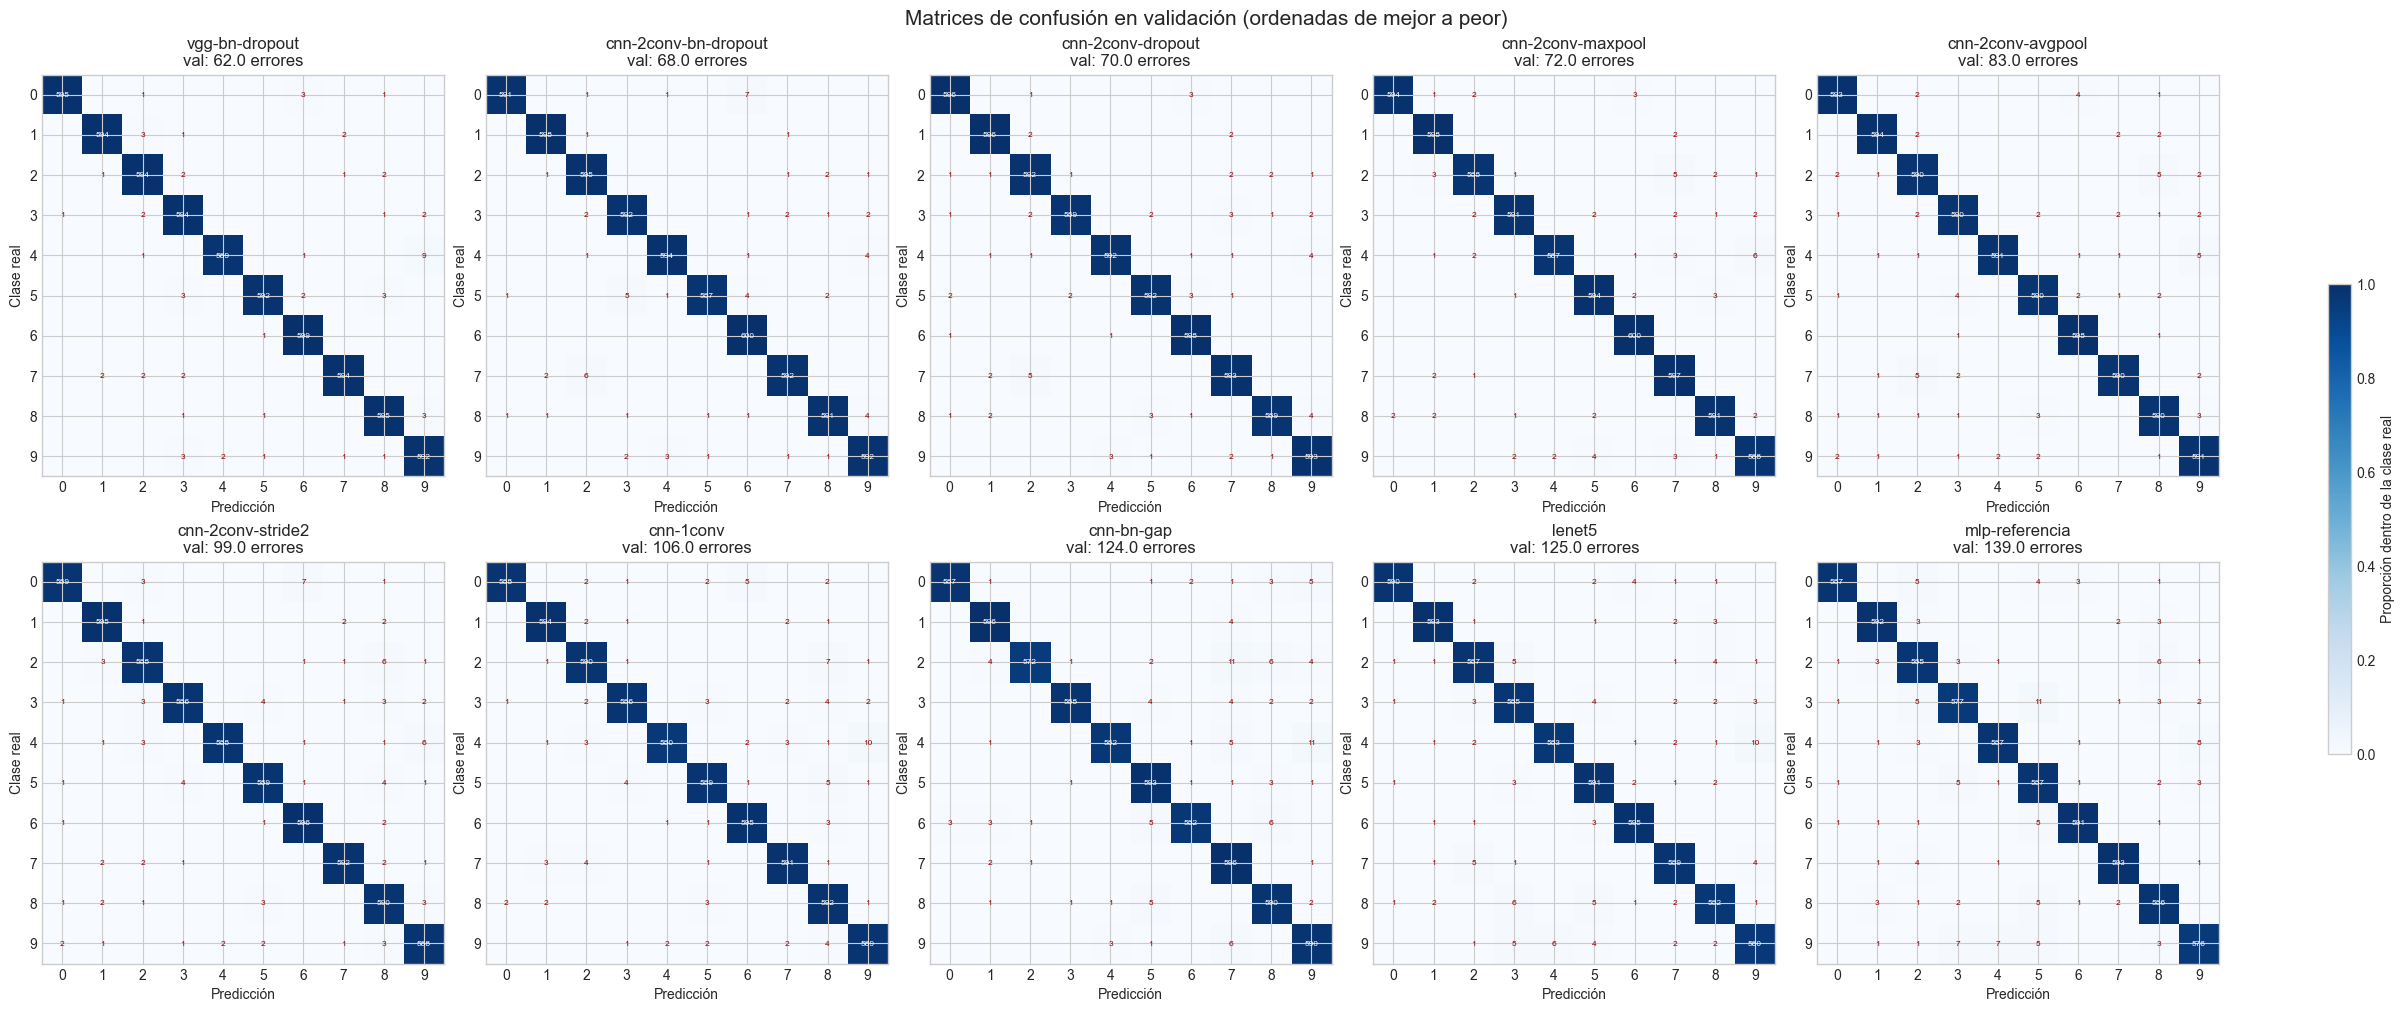

,configuration,confusión 1,confusión 2,confusión 3
0,vgg-bn-dropout,4→9 (9),9→3 (3),1→2 (3)
1,cnn-2conv-bn-dropout,0→6 (7),7→2 (6),5→3 (5)
2,cnn-2conv-dropout,7→2 (5),4→9 (4),8→9 (4)
3,cnn-2conv-maxpool,4→9 (6),2→7 (5),9→5 (4)
4,cnn-2conv-avgpool,4→9 (5),7→2 (5),2→8 (5)
5,cnn-2conv-stride2,0→6 (7),4→9 (6),2→8 (6)
6,cnn-1conv,4→9 (10),2→8 (7),5→8 (5)
7,cnn-bn-gap,4→9 (11),2→7 (11),2→8 (6)
8,lenet5,4→9 (10),8→3 (6),9→4 (6)
9,mlp-referencia,3→5 (11),4→9 (8),9→4 (7)


In [8]:
def draw_confusion_matrix(ax, matrix, title, fontsize=6):
    normalized = matrix / matrix.sum(axis=1, keepdims=True)
    image = ax.imshow(normalized, cmap='Blues', vmin=0, vmax=1)
    ax.set(title=title, xlabel='Predicción', ylabel='Clase real', xticks=CLASSES, yticks=CLASSES)
    for i in CLASSES:
        for j in CLASSES:
            if matrix[i, j]:
                ax.text(j, i, matrix[i, j], ha='center', va='center', fontsize=fontsize,
                        color='white' if normalized[i, j] > 0.5 else 'darkred')
    return image


fig, axes = plt.subplots(2, 5, figsize=(24, 10), layout='constrained')
for ax, name in zip(axes.flat, results_df['configuration']):
    row = results_df.set_index('configuration').loc[name]
    image = draw_confusion_matrix(ax, confusion_matrices[f'{name}_val'], f"{name}\nval: {row['val_errors']} errores")
fig.colorbar(image, ax=axes, shrink=0.5, label='Proporción dentro de la clase real')
fig.suptitle('Matrices de confusión en validación (ordenadas de mejor a peor)', fontsize=15)
plt.show()

top_confusions = []
for name in results_df['configuration']:
    matrix = confusion_matrices[f'{name}_val'].copy()
    np.fill_diagonal(matrix, 0)
    pairs = np.dstack(np.unravel_index(np.argsort(matrix, axis=None)[::-1][:3], matrix.shape))[0]
    top_confusions.append({'configuration': name, **{
        f'confusión {k + 1}': f'{i}→{j} ({matrix[i, j]})' for k, (i, j) in enumerate(pairs)
    }})
display(pd.DataFrame(top_confusions))

## 5. Modelo seleccionado: evaluación final y persistencia

Se recarga el fichero `.keras` guardado, se comprueba que reproduce exactamente su resultado de validación y solo entonces se evalúa en test. A continuación se muestran, a título **informativo**, las métricas de test de todas las arquitecturas para comprobar si la ordenación por validación se mantiene en datos nunca vistos. Estos valores no se han utilizado para elegir el modelo.

Mejor configuración: vgg-bn-dropout
Parámetros: 468,394
Entrenamiento: exactitud=99.3889%; errores=330/54000
Validación:    exactitud=98.9667%; errores=62/6000
Test:          exactitud=99.1800%; errores=82/10000
Tiempo de entrenamiento: 363.2 s (10 épocas, pesos de la época 7)
Modelo guardado en: /Users/jalcausa/Documents/Carrera/Cuarto/Aprendizaje-Computacional-II/Tema-2-RNN-Convolucionales/Practica-3/mejor_modelo_cnn_mnist.keras


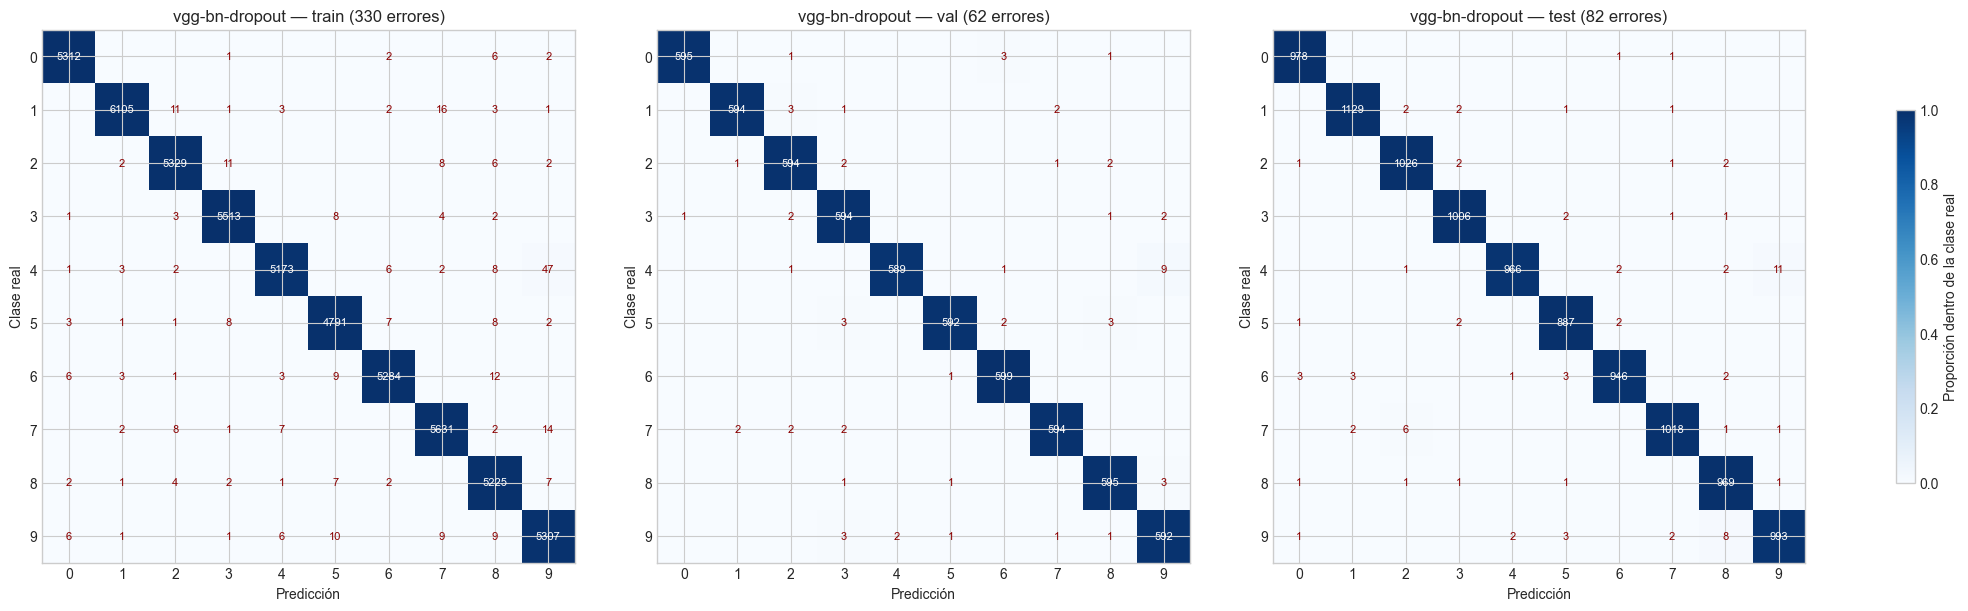

dígito,0,1,2,3,4,5,6,7,8,9
ejemplos,980.000000,1135.000000,1032.000000,1010.000000,982.000000,892.000000,958.000000,1028.000000,974.000000,1009.000000
errores,2.000000,6.000000,6.000000,4.000000,16.000000,5.000000,12.000000,10.000000,5.000000,16.000000
exactitud,0.9980,0.9947,0.9942,0.9960,0.9837,0.9944,0.9875,0.9903,0.9949,0.9841


In [9]:
best_model = tf.keras.models.load_model(model_path)
best_row = results_df.iloc[0]
reloaded_accuracy, reloaded_errors, _, _ = evaluate_predictions(best_model, x_val, y_val)
if not np.isclose(reloaded_accuracy, best_row['val_accuracy']) or reloaded_errors != best_row['val_errors']:
    raise RuntimeError('El modelo recuperado no reproduce el resultado de validación')

test_accuracy, test_errors, test_matrix, test_predictions = evaluate_predictions(best_model, x_test, y_test)
assert test_errors == test_results[best_name][1]
confusion_matrices[f'{best_name}_test'] = test_matrix
np.savez_compressed(BASE_DIR / 'matrices_confusion.npz', **confusion_matrices)

results_df['test_accuracy'] = results_df['configuration'].map(lambda name: test_results[name][0])
results_df['test_errors'] = results_df['configuration'].map(lambda name: test_results[name][1])
results_df.to_csv(BASE_DIR / 'resultados_configuraciones.csv', index=False)

print('Mejor configuración:', best_name)
print(f'Parámetros: {best_model.count_params():,}')
print(f"Entrenamiento: exactitud={best_row['train_accuracy']:.4%}; errores={best_row['train_errors']}/{len(y_fit)}")
print(f'Validación:    exactitud={reloaded_accuracy:.4%}; errores={reloaded_errors}/{len(y_val)}')
print(f'Test:          exactitud={test_accuracy:.4%}; errores={test_errors}/{len(y_test)}')
print(f"Tiempo de entrenamiento: {best_row['train_seconds']:.1f} s ({best_row['epochs_run']} épocas, pesos de la época {best_row['restored_epoch']})")
print('Modelo guardado en:', model_path.resolve())

fig, axes = plt.subplots(1, 3, figsize=(20, 6), layout='constrained')
for ax, split in zip(axes, ('train', 'val', 'test')):
    matrix = confusion_matrices[f'{best_name}_{split}']
    image = draw_confusion_matrix(ax, matrix, f'{best_name} — {split} ({matrix.sum() - np.trace(matrix)} errores)', fontsize=8)
fig.colorbar(image, ax=axes, shrink=0.7, label='Proporción dentro de la clase real')
plt.show()

per_class = pd.DataFrame({'ejemplos': np.bincount(y_test, minlength=10), 'errores': np.bincount(y_test[test_predictions != y_test], minlength=10)})
per_class['exactitud'] = 1 - per_class['errores'] / per_class['ejemplos']
display(per_class.rename_axis('dígito').T.style.format('{:.4f}', subset=pd.IndexSlice[['exactitud'], :]))

,configuration,parameters,val_accuracy,val_errors,test_accuracy,test_errors,rank_val,rank_test
0,vgg-bn-dropout,"468,394",98.967%,62,99.180%,82,1,3
1,cnn-2conv-bn-dropout,"225,322",98.867%,68,99.220%,78,2,1
2,cnn-2conv-dropout,"225,034",98.833%,70,99.190%,81,3,2
3,cnn-2conv-maxpool,"225,034",98.800%,72,98.830%,117,4,5
4,cnn-2conv-avgpool,"225,034",98.617%,83,98.840%,116,5,4
5,cnn-2conv-stride2,"315,146",98.350%,99,98.620%,138,6,6
6,cnn-1conv,"693,962",98.233%,106,98.490%,151,7,7
7,cnn-bn-gap,"94,634",97.933%,124,98.120%,188,8,9
8,lenet5,"61,706",97.917%,125,98.410%,159,9,8
9,mlp-referencia,"101,770",97.683%,139,97.710%,229,10,10


Correlación de Spearman entre el orden de validación y el de test: 0.939


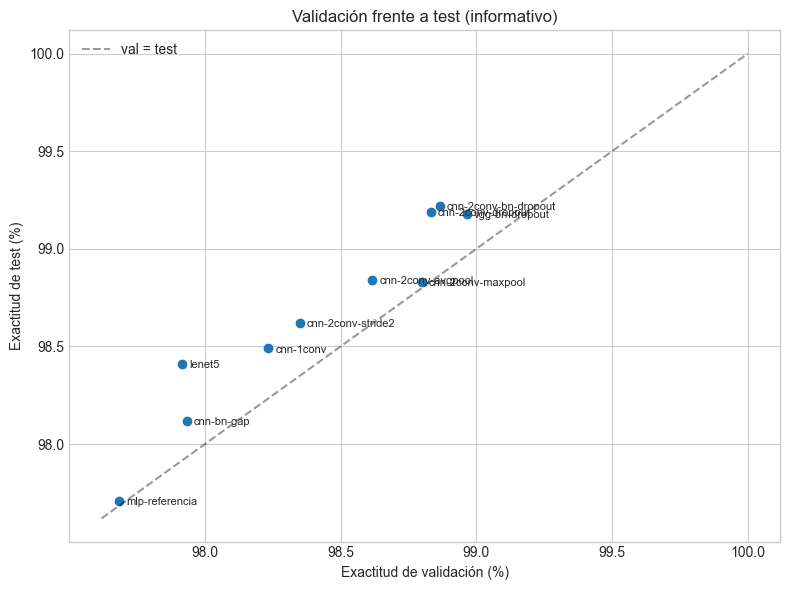

In [10]:
comparison = results_df[['configuration', 'parameters', 'val_accuracy', 'val_errors', 'test_accuracy', 'test_errors']].copy()
comparison['rank_val'] = np.arange(1, len(comparison) + 1)
comparison['rank_test'] = comparison['test_accuracy'].rank(ascending=False, method='min').astype(int)
display(comparison.style.format({'parameters': '{:,}', 'val_accuracy': '{:.3%}', 'test_accuracy': '{:.3%}'}))
spearman = comparison[['val_accuracy', 'test_accuracy']].corr(method='spearman').iloc[0, 1]
print(f'Correlación de Spearman entre el orden de validación y el de test: {spearman:.3f}')

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(comparison['val_accuracy'] * 100, comparison['test_accuracy'] * 100)
for _, row in comparison.iterrows():
    ax.annotate(row['configuration'], (row['val_accuracy'] * 100, row['test_accuracy'] * 100), fontsize=8, xytext=(5, -3), textcoords='offset points')
lims = [min(ax.get_xlim()[0], ax.get_ylim()[0]), 100]
ax.plot(lims, lims, 'k--', alpha=0.4, label='val = test')
ax.set(xlabel='Exactitud de validación (%)', ylabel='Exactitud de test (%)', title='Validación frente a test (informativo)')
ax.legend()
plt.tight_layout()
plt.show()

### Qué ha aprendido la red y dónde se equivoca

Se visualizan los mapas de activación de la primera capa convolucional del mejor modelo para un dígito (cada filtro responde a un tipo de trazo u orientación) y una muestra de los errores de test con la probabilidad asignada.

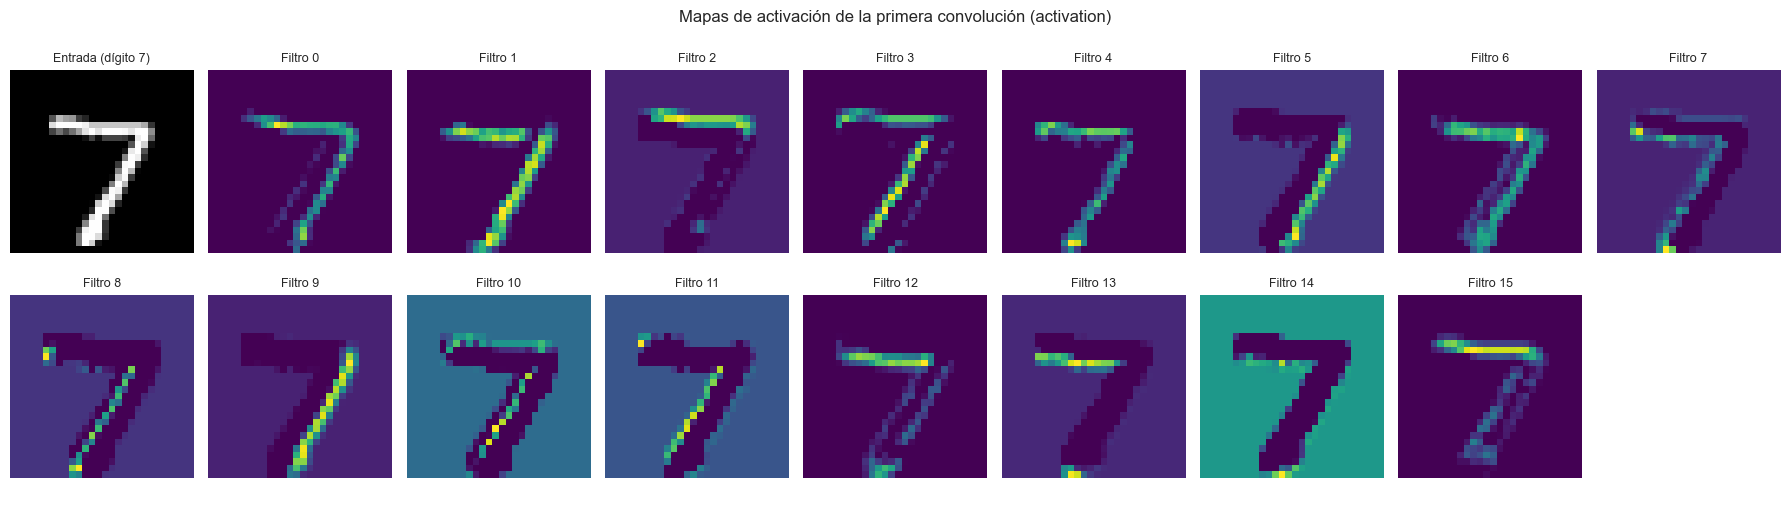

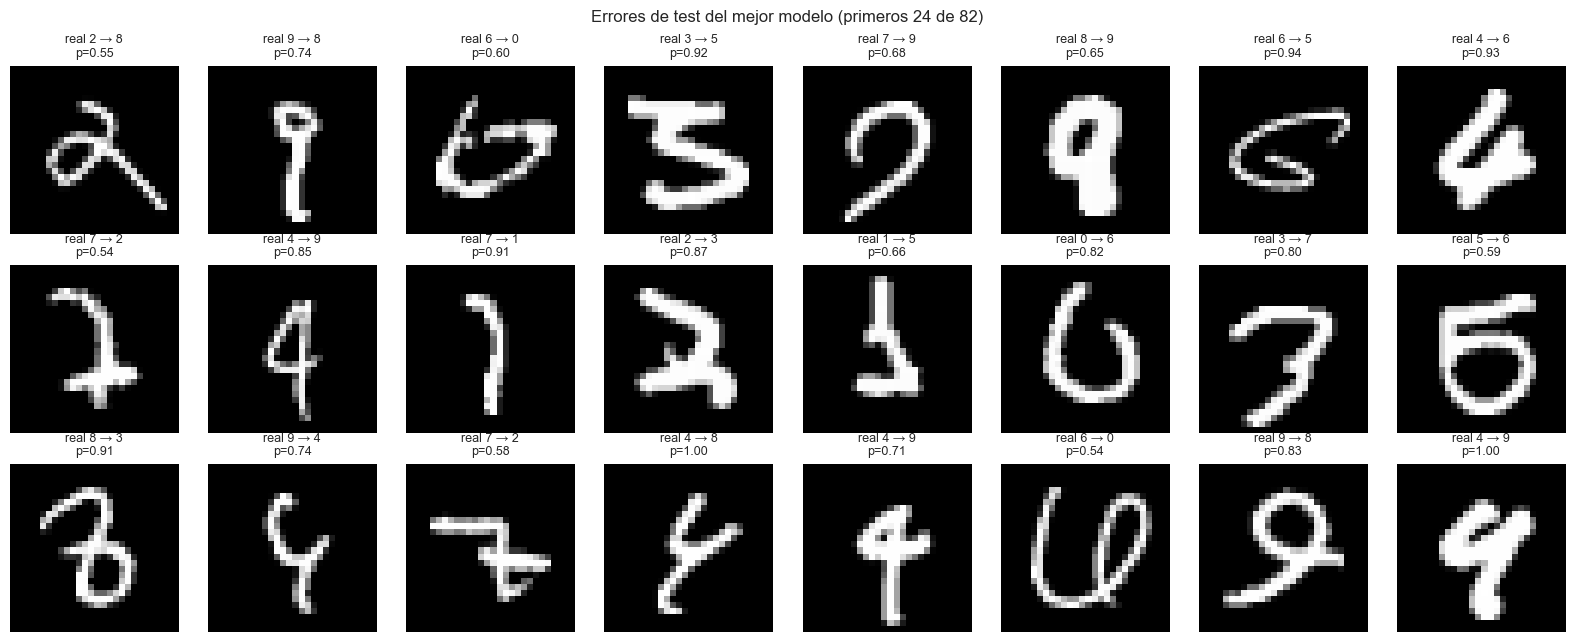

In [11]:
first_conv = next(layer for layer in best_model.layers if isinstance(layer, layers.Conv2D))
activation_after = first_conv if first_conv.get_config()['activation'] != 'linear' else next(
    layer for layer in best_model.layers[best_model.layers.index(first_conv):] if isinstance(layer, layers.Activation))
feature_extractor = tf.keras.Model(best_model.inputs, activation_after.output)
sample = x_test[:1]
feature_maps = feature_extractor.predict(sample, verbose=0)[0]

fig, axes = plt.subplots(2, 9, figsize=(18, 5.2))
axes.flat[0].imshow(sample[0, ..., 0], cmap='gray')
axes.flat[0].set_title(f'Entrada (dígito {y_test[0]})', fontsize=9)
for k, ax in enumerate(axes.flat[1:min(17, feature_maps.shape[-1] + 1)]):
    ax.imshow(feature_maps[..., k], cmap='viridis')
    ax.set_title(f'Filtro {k}', fontsize=9)
for ax in axes.flat:
    ax.axis('off')
plt.suptitle(f'Mapas de activación de la primera convolución ({activation_after.name})')
plt.tight_layout()
plt.show()

probabilities = best_model.predict(x_test, batch_size=512, verbose=0)
wrong = np.flatnonzero(test_predictions != y_test)
fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
for ax, index in zip(axes.flat, wrong):
    ax.imshow(x_test[index, ..., 0], cmap='gray')
    ax.set_title(f'real {y_test[index]} → {test_predictions[index]}\np={probabilities[index].max():.2f}', fontsize=9)
for ax in axes.flat:
    ax.axis('off')
plt.suptitle(f'Errores de test del mejor modelo (primeros {min(len(wrong), axes.size)} de {len(wrong)})')
plt.tight_layout()
plt.show()

### Reutilización del modelo guardado

El fichero se puede cargar en otro programa sin redefinir la arquitectura. La entrada debe ser `float32` con forma `(n, 28, 28, 1)` y valores en $[0,1]$.

In [12]:
reused_model = tf.keras.models.load_model(BASE_DIR / 'mejor_modelo_cnn_mnist.keras')
new_images = images_test[:8]
predicted = np.argmax(reused_model.predict(preprocess(new_images), verbose=0), axis=1)
print('Predicción:', predicted)
print('Real:      ', digits_test[:8])

Predicción: [7 2 1 0 4 1 4 9]
Real:       [7 2 1 0 4 1 4 9]



## 6. Interpretación y conclusiones

| # | Arquitectura | Parámetros | Épocas (pesos usados) | Exactitud train | Exactitud val | Errores val | Errores test* | Tiempo CPU |
|:-:|:--|--:|--:|--:|--:|--:|--:|--:|
| 1 | **`vgg-bn-dropout`** | **468 394** | **10 (7)** | **99,389 %** | **98,967 %** | **62** | **82** | **363 s** |
| 2 | `cnn-2conv-bn-dropout` | 225 322 | 15 (14) | 99,591 % | 98,867 % | 68 | 78 | 115 s |
| 3 | `cnn-2conv-dropout` | 225 034 | 14 (11) | 99,630 % | 98,833 % | 70 | 81 | 72 s |
| 4 | `cnn-2conv-maxpool` | 225 034 | 9 (6) | 99,517 % | 98,800 % | 72 | 117 | 42 s |
| 5 | `cnn-2conv-avgpool` | 225 034 | 9 (6) | 99,309 % | 98,617 % | 83 | 116 | 40 s |
| 6 | `cnn-2conv-stride2` | 315 146 | 7 (4) | 99,319 % | 98,350 % | 99 | 138 | 13 s |
| 7 | `cnn-1conv` | 693 962 | 8 (5) | 99,354 % | 98,233 % | 106 | 151 | 20 s |
| 8 | `cnn-bn-gap` | 94 634 | 13 (10) | 98,970 % | 97,933 % | 124 | 188 | 185 s |
| 9 | `lenet5` | 61 706 | 10 (7) | 99,376 % | 97,917 % | 125 | 159 | 26 s |
| 10 | `mlp-referencia` | 101 770 | 15 (13) | 99,574 % | 97,683 % | 139 | 229 | 5 s |

\* El test es informativo: no se ha usado para elegir. Validación: 6 000 imágenes; test: 10 000. Los tiempos son de CPU (Apple M3) y solo orientativos.

### Efecto de cada elemento (comparaciones por pares)

1. **Convolución frente a capa densa (1 → 3 y 1 → 9).** Todas las CNN superan al MLP de la práctica 1. Con una única convolución los errores de validación bajan de 139 a 106 y los de test de 229 a 151. No se debe solo a tener más parámetros: **LeNet-5, con un 40 % menos de parámetros que el MLP**, también comete menos errores (125 frente a 139 en validación; 159 frente a 229 en test). El MLP es además la red con mayor brecha entre entrenamiento y validación (1,89 puntos): memoriza píxeles concretos en lugar de patrones locales. La localidad, los pesos compartidos y el agrupamiento son un sesgo inductivo adecuado para las imágenes.
2. **Profundidad (3 → 4).** Una segunda convolución y un segundo pooling reducen los errores de validación de 106 a 72 y **los parámetros en un 68 %** (de 694 000 a 225 000). La razón es que la salida de `Flatten` pasa de 13·13·32 = 5 408 a 5·5·64 = 1 600 valores, y la capa densa concentra casi todos los parámetros. La segunda capa combina los trazos detectados por la primera (bordes → partes de dígitos) y amplía el campo receptivo.
3. **Max frente a average pooling (4 → 5).** MaxPooling da 11 errores menos en validación, aunque ambas coinciden en test (117 frente a 116). Max conserva la respuesta más intensa de cada ventana, es decir, *si* aparece un trazo, mientras que la media lo diluye con el fondo negro. La ventaja es pequeña y no concluyente.
4. ***Stride* 2 frente a pooling (4 → 6).** Reducir la resolución con convoluciones de paso 2 es la CNN más rápida (1,8 s/época frente a 4,7 s), pero obtiene 27 errores más en validación: con un filtro 3×3 y paso 2 se analizan menos posiciones y se pierde detalle espacial, como se indicaba en las diapositivas.
5. **Dropout (4 → 7).** La mejora en validación es pequeña (72 → 70), pero produce la **menor pérdida de validación de todas** (0,035 frente a 0,044) y en test pasa de 117 a 81 errores. Sin Dropout la pérdida de validación empieza a subir en la época 6; con Dropout puede entrenarse 11 épocas útiles sin sobreajustar. A cambio necesita más épocas y tiempo.
6. **BatchNormalization (7 → 8).** Añadir BN tras cada convolución mejora ligeramente (70 → 68 en validación, 81 → 78 en test) y es el mejor modelo en test, pero cada época cuesta un 50 % más. Sus mejores pesos son de la época 14 de 15, lo que indica que **aún no había convergido**: con más épocas podría mejorar.
7. **Global Average Pooling (8 → 9).** Sustituir `Flatten` + `Dense` por GAP reduce los parámetros a 95 000, pero es la peor CNN salvo LeNet: 124 errores de validación y 188 de test. Además, es lenta (convoluciones `same` de 128 filtros) y la pérdida de validación es inestable (picos en las épocas 4 y 11-12). Promediar cada mapa elimina **dónde** aparece cada rasgo, y en un dígito la posición relativa de los trazos es esencial (un 4 y un 9 tienen rasgos similares en lugares distintos). GAP funciona en redes profundas como GoogLeNet, que tienen campos receptivos grandes; con solo tres capas resulta insuficiente.
8. **Bloques tipo VGG (8 → 10).** Duplicar las convoluciones 3×3 de cada bloque da el mejor resultado de validación: 62 errores, la menor pérdida de validación entre los modelos con BN y **la menor brecha de todas** (0,42 puntos). Cada par de convoluciones 3×3 tiene un campo receptivo de 5×5 con menos parámetros y una no linealidad más. A cambio, el entrenamiento es unas 3 veces más lento que la red 8 y 5 veces más que la 7.
9. **LeNet-5** es la CNN más pequeña (61 706 parámetros). Supera al MLP, pero queda por detrás de las redes modernas con ReLU y MaxPooling: `tanh` se satura y el *average pooling* reduce el contraste. Esto coincide con la evolución histórica descrita en clase (AlexNet → ReLU y max pooling; VGG → bloques 3×3 más profundos).

### ¿Qué configuración obtiene el mejor rendimiento?

Según el criterio fijado de antemano (exactitud de validación), la mejor configuración es **`vgg-bn-dropout`**:

- dos bloques con dos capas `Conv2D` 3×3 de *padding* `same` cada una (32 y 64 filtros), sin sesgo y seguidas de `BatchNormalization` → `ReLU`;
- tras cada bloque, `MaxPooling2D` 2×2 y `Dropout(0,25)`;
- después, `Flatten` → `Dense(128, ReLU)` → `Dropout(0,5)` → `Dense(10, softmax)`;
- Adam (tasa por defecto), lote 128, parada temprana con *patience* 3 y pesos restaurados de la época 7.

Resultados: **98,967 % en validación (62 errores de 6 000)** y **99,18 % en test (82 errores de 10 000)**. Frente al MLP de la práctica 1 en las mismas condiciones (97,71 % en test, 229 errores), los errores de test bajan un **64 %**. La matriz de confusión de test es casi diagonal. Los dígitos con más errores son el 4 y el 9 (16 cada uno) y el 6 (12). La confusión más frecuente es 4 → 9 (11 casos), seguida de 9 → 8 (8) y 7 → 2 (6). Son grafías que se parecen, y varios ejemplos mal clasificados resultan ambiguos incluso para una persona.

Matices:

- **Las tres mejores redes están en empate técnico.** En test, `cnn-2conv-bn-dropout` (78 errores) y `cnn-2conv-dropout` (81) quedan incluso por delante del ganador (82). Diferencias de 4 imágenes de 10 000 están dentro de la variación debida a la semilla y a la muestra. Aun así, la ordenación por validación y por test es muy parecida (correlación de Spearman 0,94) y la selección no se ha cambiado mirando el test.
- **Rendimiento frente a coste.** Si el tiempo de entrenamiento o el tamaño del modelo importan, `cnn-2conv-dropout` ofrece prácticamente la misma exactitud con la mitad de parámetros y una quinta parte del tiempo.
- **Lo que tienen en común las mejores redes:** al menos dos niveles de convolución con ReLU, MaxPooling y regularización (Dropout y/o BatchNorm). La regularización permite entrenar más épocas sin que la validación empeore.
- **Limitaciones:** se ha usado una única semilla, 15 épocas como máximo y los hiperparámetros de entrenamiento fijos de la práctica 1. Para afirmar con seguridad que una arquitectura es mejor habría que repetir con varias semillas o con validación cruzada. También podría aprovecharse el aumento de datos (pequeñas rotaciones y traslaciones).

El modelo se ha guardado en **`mejor_modelo_cnn_mnist.keras`**. Recibe imágenes `float32` de forma `(n, 28, 28, 1)` con valores en $[0,1]$ y devuelve las diez probabilidades *softmax*. La tabla completa está en `resultados_configuraciones.csv` y las matrices de confusión de entrenamiento y validación de todas las redes, más la de test del ganador, en `matrices_confusion.npz`.
